In [ ]:
# Mounting the drive and creating working directory
import os
os.getcwd()
os.chdir('/content/drive/MyDrive/Datasets')

# Importing the necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# importing data
df = pd.read_excel('STOCK_MOVEMENT.xlsx')
df

,item_code,item_name,date,reference,description,client,quantity,movement_type,purpose,source_location,destination_location,created_by,prev_stock_qty,price,amount,stock_invoice
0,ST01481,PREDNISOLONE 5MG- COSMOS,2026-05-31 00:00:00,578412,Stock_Adjustment Adjustment,NaN,3000,Stock_Adjustment,Adjustment,Main Store,NaN,rose.kabaka,0.0,1.98,5940.0,NaN
1,ST02397,FUCLEAR V PESSARIES 6'S,2026-05-31 00:00:00,578574,Stock_Entry Transfer,NaN,-10,Stock_Entry,Transfer,Main Store,Pharmacy,rose.kabaka,10.0,425.00,4250.0,NaN
2,ST01063,ISOCET P 100ML,2026-05-31 00:00:00,578574,Stock_Entry Transfer,NaN,-20,Stock_Entry,Transfer,Main Store,Pharmacy,rose.kabaka,50.0,102.00,2040.0,NaN
3,ST00337,CEFOTIL (CEFUROXIME) 70ML,2026-05-31 00:00:00,578640,Stock_Entry Transfer,NaN,-5,Stock_Entry,Transfer,Main Store,Pharmacy,rose.kabaka,20.0,590.00,2950.0,NaN
4,ST01788,TUSPEL COUGH 100ML SYR,2026-05-31 00:00:00,578692,Stock_Entry Transfer,NaN,-9,Stock_Entry,Transfer,Main Store,Pharmacy,rose.kabaka,9.0,207.00,1863.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,ST00818,FUNBACT A CREAM,2026-05-18 00:00:00,567785,Stock_Entry Transfer,NaN,-10,Stock_Entry,Transfer,Main Store,Bash Store,stephanie.nyawira,10.0,198.90,1989.0,NaN
996,ST02636,HER KIT,2026-05-18 00:00:00,567785,Stock_Entry Transfer,NaN,-1,Stock_Entry,Transfer,Main Store,Bash Store,stephanie.nyawira,15.0,463.50,463.5,NaN
997,ST01344,OG KIT,2026-05-18 00:00:00,567785,Stock_Entry Transfer,NaN,-1,Stock_Entry,Transfer,Main Store,Bash Store,stephanie.nyawira,50.0,396.00,396.0,NaN
998,ST04136,GYNAGONE KIT,2026-05-18 00:00:00,567785,Stock_Entry Transfer,NaN,-1,Stock_Entry,Transfer,Main Store,Bash Store,stephanie.nyawira,6.0,470.00,470.0,NaN


# **Data Exploration**

In [ ]:
# checking for the shape of the data
df.shape

(1000, 16)

In [ ]:
print("--- SHAPE ---")
print(df.shape)

print("\n--- INFO ---")
df.info()

print("\n--- FIRST 3 ROWS ---")
display(df.head(3))

--- SHAPE ---
(1000, 16)

--- INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   item_code             1000 non-null   object 
 1   item_name             1000 non-null   object 
 2   date                  1000 non-null   object 
 3   reference             1000 non-null   object 
 4   description           995 non-null    object 
 5   client                5 non-null      float64
 6   quantity              1000 non-null   object 
 7   movement_type         1000 non-null   object 
 8   purpose               1000 non-null   object 
 9   source_location       999 non-null    object 
 10  destination_location  736 non-null    object 
 11  created_by            1000 non-null   object 
 12  prev_stock_qty        982 non-null    float64
 13  price                 1000 non-null   float64
 14  amount                996 non-null

,item_code,item_name,date,reference,description,client,quantity,movement_type,purpose,source_location,destination_location,created_by,prev_stock_qty,price,amount,stock_invoice
0,ST01481,PREDNISOLONE 5MG- COSMOS,2026-05-31 00:00:00,578412,Stock_Adjustment Adjustment,NaN,3000,Stock_Adjustment,Adjustment,Main Store,NaN,rose.kabaka,0.0,1.98,5940.0,NaN
1,ST02397,FUCLEAR V PESSARIES 6'S,2026-05-31 00:00:00,578574,Stock_Entry Transfer,NaN,-10,Stock_Entry,Transfer,Main Store,Pharmacy,rose.kabaka,10.0,425.00,4250.0,NaN
2,ST01063,ISOCET P 100ML,2026-05-31 00:00:00,578574,Stock_Entry Transfer,NaN,-20,Stock_Entry,Transfer,Main Store,Pharmacy,rose.kabaka,50.0,102.00,2040.0,NaN


In [ ]:
#checking for all the data types in the dataset
df.dtypes

,0
item_code,object
item_name,object
date,object
reference,object
description,object
client,float64
quantity,object
movement_type,object
purpose,object
source_location,object


The dataset contains categorical, numerical, and date-time variables:

### Categorical Variable

- item_code
- item_name
- reference
- description
- client
- movement_type
- purpose
- source_location
- destination_location
- created_by
- stock_invoice

### Numerical Variable

- quantity
- prev_stock_qty
- price
- amount

### Date-Time Variable

- date

---

### Data Type Errors Identified

- **date**: Stored as an object data type instead of datetime64[ns], preventing chronological ordering and time-based aggregation.
- **quantity**: Stored as an object data type instead of a numeric format (float64 or int64), restricting arithmetic calculations and sum metrics.
- **client**: Stored as float64 due to excessive missing values (NaN), but should conceptually be treated as a categorical identifier.

Let's Fix that...

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   item_code             1000 non-null   object 
 1   item_name             1000 non-null   object 
 2   date                  1000 non-null   object 
 3   reference             1000 non-null   object 
 4   description           995 non-null    object 
 5   client                5 non-null      float64
 6   quantity              1000 non-null   object 
 7   movement_type         1000 non-null   object 
 8   purpose               1000 non-null   object 
 9   source_location       999 non-null    object 
 10  destination_location  736 non-null    object 
 11  created_by            1000 non-null   object 
 12  prev_stock_qty        982 non-null    float64
 13  price                 1000 non-null   float64
 14  amount                996 non-null    float64
 15  stock_invoice         

In [ ]:
df.tail()

,item_code,item_name,date,reference,description,client,quantity,movement_type,purpose,source_location,destination_location,created_by,prev_stock_qty,price,amount,stock_invoice
995,ST00818,FUNBACT A CREAM,2026-05-18 00:00:00,567785,Stock_Entry Transfer,NaN,-10,Stock_Entry,Transfer,Main Store,Bash Store,stephanie.nyawira,10.0,198.9,1989.0,NaN
996,ST02636,HER KIT,2026-05-18 00:00:00,567785,Stock_Entry Transfer,NaN,-1,Stock_Entry,Transfer,Main Store,Bash Store,stephanie.nyawira,15.0,463.5,463.5,NaN
997,ST01344,OG KIT,2026-05-18 00:00:00,567785,Stock_Entry Transfer,NaN,-1,Stock_Entry,Transfer,Main Store,Bash Store,stephanie.nyawira,50.0,396.0,396.0,NaN
998,ST04136,GYNAGONE KIT,2026-05-18 00:00:00,567785,Stock_Entry Transfer,NaN,-1,Stock_Entry,Transfer,Main Store,Bash Store,stephanie.nyawira,6.0,470.0,470.0,NaN
999,ST00838,GENTAMYCIN DROPS,2026-05-18 00:00:00,567785,Stock_Entry Transfer,NaN,-20,Stock_Entry,Transfer,Main Store,Bash Store,stephanie.nyawira,30.0,18.0,360.0,NaN


In [ ]:
df.head()

,item_code,item_name,date,reference,description,client,quantity,movement_type,purpose,source_location,destination_location,created_by,prev_stock_qty,price,amount,stock_invoice
0,ST01481,PREDNISOLONE 5MG- COSMOS,2026-05-31 00:00:00,578412,Stock_Adjustment Adjustment,NaN,3000,Stock_Adjustment,Adjustment,Main Store,NaN,rose.kabaka,0.0,1.98,5940.0,NaN
1,ST02397,FUCLEAR V PESSARIES 6'S,2026-05-31 00:00:00,578574,Stock_Entry Transfer,NaN,-10,Stock_Entry,Transfer,Main Store,Pharmacy,rose.kabaka,10.0,425.00,4250.0,NaN
2,ST01063,ISOCET P 100ML,2026-05-31 00:00:00,578574,Stock_Entry Transfer,NaN,-20,Stock_Entry,Transfer,Main Store,Pharmacy,rose.kabaka,50.0,102.00,2040.0,NaN
3,ST00337,CEFOTIL (CEFUROXIME) 70ML,2026-05-31 00:00:00,578640,Stock_Entry Transfer,NaN,-5,Stock_Entry,Transfer,Main Store,Pharmacy,rose.kabaka,20.0,590.00,2950.0,NaN
4,ST01788,TUSPEL COUGH 100ML SYR,2026-05-31 00:00:00,578692,Stock_Entry Transfer,NaN,-9,Stock_Entry,Transfer,Main Store,Pharmacy,rose.kabaka,9.0,207.00,1863.0,NaN


In [ ]:
# This turns 'Stock_Entry' and any other bad text into numeric missing blanks (NaN) so it will cease from
# returning an error when changing the data type in the next step
df['quantity'] = pd.to_numeric(df['quantity'], errors='coerce')

In [ ]:
# Fixing the data types error
df = df.astype({'item_name': 'string', 'reference': 'string', 'client': 'string', 'purpose': 'string', 'source_location': 'string', 'destination_location': 'string', 'created_by': 'string', 'stock_invoice': 'string'})
df = df.astype({'quantity': 'float64', 'prev_stock_qty': 'float64', 'price': 'float64', 'amount': 'float64'})
df = df.astype({'date': 'datetime64[ns]'})



In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   item_code             1000 non-null   object        
 1   item_name             1000 non-null   string        
 2   date                  1000 non-null   datetime64[ns]
 3   reference             1000 non-null   string        
 4   description           995 non-null    object        
 5   client                5 non-null      string        
 6   quantity              995 non-null    float64       
 7   movement_type         1000 non-null   object        
 8   purpose               1000 non-null   string        
 9   source_location       999 non-null    string        
 10  destination_location  736 non-null    string        
 11  created_by            1000 non-null   string        
 12  prev_stock_qty        982 non-null    float64       
 13  price              

- I have successfully converted the object dtypes to strings and ammount and price columns to float to enable computation of measures of central tendancy.
- The date Column has also been transformed into date time format.
- Now that the data types are in their correct  format, we can proceed to the next phase of the project.

In [ ]:
# I c hange the created_by column and Replace the dot with a space, then capitalize each name
df['created_by'] = df['created_by'].str.replace('.', ' ', regex=False).str.title()

In [ ]:
df.head()

,item_code,item_name,date,reference,description,client,quantity,movement_type,purpose,source_location,destination_location,created_by,prev_stock_qty,price,amount,stock_invoice
0,ST01481,PREDNISOLONE 5MG- COSMOS,2026-05-31,578412,Stock_Adjustment Adjustment,<NA>,3000.0,Stock_Adjustment,Adjustment,Main Store,<NA>,Rose Kabaka,0.0,1.98,5940.0,<NA>
1,ST02397,FUCLEAR V PESSARIES 6'S,2026-05-31,578574,Stock_Entry Transfer,<NA>,-10.0,Stock_Entry,Transfer,Main Store,Pharmacy,Rose Kabaka,10.0,425.00,4250.0,<NA>
2,ST01063,ISOCET P 100ML,2026-05-31,578574,Stock_Entry Transfer,<NA>,-20.0,Stock_Entry,Transfer,Main Store,Pharmacy,Rose Kabaka,50.0,102.00,2040.0,<NA>
3,ST00337,CEFOTIL (CEFUROXIME) 70ML,2026-05-31,578640,Stock_Entry Transfer,<NA>,-5.0,Stock_Entry,Transfer,Main Store,Pharmacy,Rose Kabaka,20.0,590.00,2950.0,<NA>
4,ST01788,TUSPEL COUGH 100ML SYR,2026-05-31,578692,Stock_Entry Transfer,<NA>,-9.0,Stock_Entry,Transfer,Main Store,Pharmacy,Rose Kabaka,9.0,207.00,1863.0,<NA>


In [ ]:
df = df.rename(columns={'quantity': 'qty', 'reference': 'ref_no',})

- Duplicate Rows Check

In [ ]:
df.duplicated().sum()

np.int64(0)

- There's zero duplicates in this dataset meaning that every row is a unique transaction record.

# Missing Values

In [ ]:
df.isnull().sum()


,0
item_code,0
item_name,0
date,0
ref_no,0
description,5
client,995
qty,5
movement_type,0
purpose,0
source_location,1


- There are a number of missing values in the dataset which will require cleaning.

In [ ]:
# Let's check the percentages of the columnns with missing data
missing = df.isnull().sum()
pct = (missing / len(df) * 100).round(1)
report = pd.DataFrame({"missing": missing, "percent": pct})
print(report[report["missing"] > 0].sort_values("missing", ascending=False))


                      missing  percent
client                    995     99.5
stock_invoice             772     77.2
destination_location      264     26.4
prev_stock_qty             18      1.8
description                 5      0.5
qty                         5      0.5
amount                      4      0.4
source_location             1      0.1


- The above  output gives us a clear distiction on the percentage of missing data in their respective column.
- Client, stock_invoice and destination_location record the highest number of missing entries at 99.5%, 77.2% and 26.4% respectively. The rest are relatively low and can be sorted out using imputation.
- Note however, that almost 100% of datain the client column is missing, this might be due to ingnorance from the clients to fill in this sction. In this scenario, I would be required to seek further clarification from the stakeholders but since it's a personal project, I  will drop the entire column because it add no value in the analysis with all the missing data.

In [ ]:
# Let's look at the rows with missing values
gaps = df[df["stock_invoice"].isnull()]
print(gaps[[ "stock_invoice", "destination_location", "qty", 'amount']].head())
print("Rows with at least one gap:", df.isnull().any(axis=1).sum())


  stock_invoice destination_location     qty  amount
0          <NA>                 <NA>  3000.0  5940.0
1          <NA>             Pharmacy   -10.0  4250.0
2          <NA>             Pharmacy   -20.0  2040.0
3          <NA>             Pharmacy    -5.0  2950.0
4          <NA>             Pharmacy    -9.0  1863.0
Rows with at least one gap: 1000



1. The <NA> Labels Confirm Clean Data Types

First, seeing <NA> instead of NaN or None means your previous step was completely successful! Your string columns are now using the modern pandas string extension type. This is excellent because pandas now explicitly treats these fields as text missing values, preventing future logic bugs.

2. The Negative Quantities (-10.0, -20.0, etc.)

Look at rows 1 through 4 under the qty column. The numbers are negative.
• Interpretation: In inventory datasets, a negative quantity almost always signifies an outbound movement, stock reduction, or sales dispatch (stock leaving a location).
• Notice that row 0 has a positive quantity (3000.0), which indicates a stock replenishment or inbound receipt (stock entering).

3. The "Pharmacy" Pattern vs. Missing Locations

• For rows 1 to 4, the destination_location is listed as Pharmacy, and the quantities are negative. This tells you exactly where the items went (they were dispatched to the Pharmacy branch/department).
• However, row 0 has a positive quantity of 3000.0 but the destination_location is <NA>. This suggests that when large stock quantities are received into the central warehouse, the destination is left blank because it hasn't been sent to a specific sub-branch yet.

4. Why client and stock_invoice are Completely Blank here

Every single row in this preview shows <NA> for both client and stock_invoice.
• For rows 1-4 (Dispatches to Pharmacy): Since the destination is an internal department (Pharmacy), there is no external client involved. Internal stock transfers usually don't generate standard external sales invoices, which explains why stock_invoice is blank.
• For row 0 (Inbound Restock): A massive receipt of 3,000 units would typically be tied to a supplier or purchase order, not a customer "client" or a customer "stock invoice".

5. "Rows with at least one gap: 1000"

This tells you that out of your entire dataset, exactly 1,000 rows contain a missing value in at least one of their columns. Given that your dataset has structural blanks (like internal transfers not needing client names), this number is normal and expected.

In [ ]:
# Let's drop the client column
print("Before:", df.shape)
df = df.drop(columns=['client'])
print("After:", df.shape)

Before: (1000, 16)
After: (1000, 15)


## Data Imputation

In [ ]:
# Creating a clean copy of the DataFrame so the raw data stays untouched
# we then apply a smart conditional fill to assign missing stock invoices as either 'MISSING_RECEIPT_ID' or 'DISPATCH_LOG' based on quantity direction.
# Then complete the two-column cleanup by filling all missing destination locations with an 'UNKNOWN' placeholder.

clean = df.copy()

invoice_conditions = [(clean['qty'] > 0) & (clean['stock_invoice'].isnull()),
 (clean['qty'] <= 0) & (clean['stock_invoice'].isnull())]

invoice_placeholders = ['MISSING_RECEIPT_ID', 'DISPATCH_LOG']
clean['stock_invoice'] = np.select(invoice_conditions, invoice_placeholders, default=clean['stock_invoice'])
clean['destination_location'] = clean['destination_location'].fillna('UNKNOWN')

source_mode = clean['source_location'].mode()[0]
clean['source_location'] = clean['source_location'].fillna(source_mode)
clean['description'] = clean['description'].fillna('UNKNOWN')


In [ ]:
# Imputin numeric columns
print("Mean of prev_stock_qty: ", round(clean['prev_stock_qty'].mean(), 2))
print("Median of prev_stock_qty: ", round(clean['prev_stock_qty'].median(), 2))
print("mean of qty: ", round(clean['qty'].mean(), 2))
print("Median of qty: ", round(clean['qty'].median(), 2))
print("Mean of amount:", round(clean['amount'].mean(), 2))
print("Median of amount:", round(clean['amount'].median(), 2))
print(" Mode of source_location:", clean['source_location'].mode()[0])



Mean of prev_stock_qty:  591.23
Median of prev_stock_qty:  35.0
mean of qty:  21.3
Median of qty:  -6.0
Mean of amount: 5046.48
Median of amount: 1900.0
 Mode of source_location: Main Store



1. Previous Stock Quantity (prev_stock_qty)

The mean is significantly higher than the median because of a few extremely large incoming stock values that pull the average upward. The median is the safer choice here because it is not distorted by these high-volume replenishment outliers.

2. Quantity (qty)

The mean is positive while the median is negative because a couple of exceptionally large bulk restock deliveries outscale the much more frequent, smaller outbound dispatches. The median is the safer choice here because it accurately reflects that the typical daily transaction is an outbound stock movement.

3. Amount (amount)

The mean is more than double the median because of a small number of high-value financial transactions that skew the overall distribution. The median is the safer choice here because it represents the true middle point of standard operational transaction costs.

In [ ]:
# This code handles missing numeric data by grouping rows sharing identical unique item codes.
# It applies a custom lambda function to isolate and calculate stable medians for each isolated product group.
# It then fills data gaps in prev_stock_qty, qty, and amount using these precise group-level averages.
clean['prev_stock_qty'] = clean.groupby('item_code')['prev_stock_qty'].transform(lambda s: s.fillna(s.median()))
clean['qty'] = clean.groupby('item_code')['qty'].transform(lambda s: s.fillna(s.median()))
clean['amount'] = clean.groupby('item_code')['amount'].transform(lambda s: s.fillna(s.median()))

In [ ]:
print("Missing prev_stock_qty left:", clean['prev_stock_qty'].isnull().sum())
print("Missing qty left:", clean['qty'].isnull().sum())
print("Missing amount left:", clean['amount'].isnull().sum())

Missing prev_stock_qty left: 12
Missing qty left: 5
Missing amount left: 2


In [ ]:
clean['prev_stock_qty'] = clean['prev_stock_qty'].fillna(clean['prev_stock_qty'].median())
clean['qty'] = clean['qty'].fillna(clean['qty'].median())
clean['amount'] = clean['amount'].fillna(clean['amount'].median())

In [ ]:
# checking if we have sorted alll teh missing values now
clean.isnull().sum()

,0
item_code,0
item_name,0
date,0
ref_no,0
description,0
qty,0
movement_type,0
purpose,0
source_location,0
destination_location,0


In [ ]:
clean['stock_invoice'] = clean['stock_invoice'].fillna('UNKNOWN_LOG')

In [ ]:
clean.isnull().sum()

,0
item_code,0
item_name,0
date,0
ref_no,0
description,0
qty,0
movement_type,0
purpose,0
source_location,0
destination_location,0


- There is no missing value left in the dataset. All the missing values have been correctly addressed.

In [ ]:
clean.head()

,item_code,item_name,date,ref_no,description,qty,movement_type,purpose,source_location,destination_location,created_by,prev_stock_qty,price,amount,stock_invoice
0,ST01481,PREDNISOLONE 5MG- COSMOS,2026-05-31,578412,Stock_Adjustment Adjustment,3000.0,Stock_Adjustment,Adjustment,Main Store,UNKNOWN,Rose Kabaka,0.0,1.98,5940.0,MISSING_RECEIPT_ID
1,ST02397,FUCLEAR V PESSARIES 6'S,2026-05-31,578574,Stock_Entry Transfer,-10.0,Stock_Entry,Transfer,Main Store,Pharmacy,Rose Kabaka,10.0,425.00,4250.0,DISPATCH_LOG
2,ST01063,ISOCET P 100ML,2026-05-31,578574,Stock_Entry Transfer,-20.0,Stock_Entry,Transfer,Main Store,Pharmacy,Rose Kabaka,50.0,102.00,2040.0,DISPATCH_LOG
3,ST00337,CEFOTIL (CEFUROXIME) 70ML,2026-05-31,578640,Stock_Entry Transfer,-5.0,Stock_Entry,Transfer,Main Store,Pharmacy,Rose Kabaka,20.0,590.00,2950.0,DISPATCH_LOG
4,ST01788,TUSPEL COUGH 100ML SYR,2026-05-31,578692,Stock_Entry Transfer,-9.0,Stock_Entry,Transfer,Main Store,Pharmacy,Rose Kabaka,9.0,207.00,1863.0,DISPATCH_LOG


## Checking for Duplicate Records

In [ ]:
duplicate_count = clean.duplicated().sum()
print(f"Total duplicate rows: {duplicate_count}")

Total duplicate rows: 0


- The output shows the total duplicate rows is zero meaning the dataset has no perfect or identical duplicate entries. However, In some instances, we might have Fuzzy duplicates which means that the dataset may often contain minor spelling differences, different timestamps, or missing fields. The main challenge has always been that duplicates are rarely 100% identical.
- So because of this logic, we have to check further and assertain that there are no fuzzy duplicate entries before progressing to handling outliers.

In [ ]:
# Check for matching transactions on core columns only
fuzzy_subset = ['date', 'item_code', 'qty', 'amount']
fuzzy_count = clean.duplicated(subset=fuzzy_subset).sum()

print(f"Fuzzy duplicate records found: {fuzzy_count}")

Fuzzy duplicate records found: 18


In [ ]:
# Isolate and sort the matching fuzzy duplicate records
fuzzy_subset = ['date', 'item_code', 'qty', 'amount']
duplicate_rows = clean[clean.duplicated(subset=fuzzy_subset, keep=False)].sort_values(by=fuzzy_subset)

# Display the top 10 rows to inspect the differences
print(duplicate_rows.head(10))

    item_code                  item_name       date  ref_no  \
811   ST01740  TISSUE PAPER (DAWN PEKEE) 2026-05-20  569219   
855   ST01740  TISSUE PAPER (DAWN PEKEE) 2026-05-20  569634   
685   ST01012          INJ MORPHINE 10MG 2026-05-22  571143   
690   ST01012          INJ MORPHINE 10MG 2026-05-22  571143   
637   ST01118      LATEX GLOVES POWDERED 2026-05-22  570913   
671   ST01118      LATEX GLOVES POWDERED 2026-05-22  571142   
696   ST02564  ETR 90MG(ETORICOXIB TABS) 2026-05-22  571147   
742   ST02564  ETR 90MG(ETORICOXIB TABS) 2026-05-22  571179   
693   ST02618    ETR 60(ETORICOXIB TABS) 2026-05-22  571147   
738   ST02618    ETR 60(ETORICOXIB TABS) 2026-05-22  571179   

              description    qty movement_type   purpose source_location  \
811  Stock_Entry Transfer  -10.0   Stock_Entry  Transfer      Main Store   
855  Stock_Entry Transfer  -10.0   Stock_Entry  Transfer      Main Store   
685  Stock_Entry Transfer  -10.0   Stock_Entry  Transfer      Main Store   
69

In [ ]:
# Capturing the duplicates I'm bout to drop for documentation purposes
fuzzy_subset = ['date', 'item_code', 'qty', 'amount']
dropped_records = clean[clean.duplicated(subset=fuzzy_subset, keep='first')]

# Printing a summary report for stakeholders
print("=== DUPLICATE REMOVAL AUDIT REPORT ===")
print(f"Total Fuzzy Duplicate Rows Dropped: {len(dropped_records)}")
print("\nSample of Dropped Items and Quantities:")
print(dropped_records[['item_code', 'qty', 'amount']].head())
print("======================================")

# Dropping the duplicates permanently from the clean dataset
clean = clean.drop_duplicates(subset=fuzzy_subset, keep='first')


=== DUPLICATE REMOVAL AUDIT REPORT ===
Total Fuzzy Duplicate Rows Dropped: 18

Sample of Dropped Items and Quantities:
    item_code    qty  amount
9     ST01063  -20.0  2040.0
188   ST02108 -160.0   153.6
295   ST04006  -50.0  1500.0
437   ST02654   -1.0   300.0
438   ST01740  -15.0   297.0


**Handling Outliers**

In [ ]:
print(clean[["prev_stock_qty", "price", "amount"]].describe().round(2))

       prev_stock_qty     price     amount
count          982.00    982.00     982.00
mean           581.23    409.84    5098.27
std           3080.73   1259.59   10212.08
min              0.00      0.00       0.00
25%              6.00     26.00     700.00
50%             34.50     83.76    1918.44
75%            282.25    334.28    5208.75
max          52000.00  19720.00  130000.00


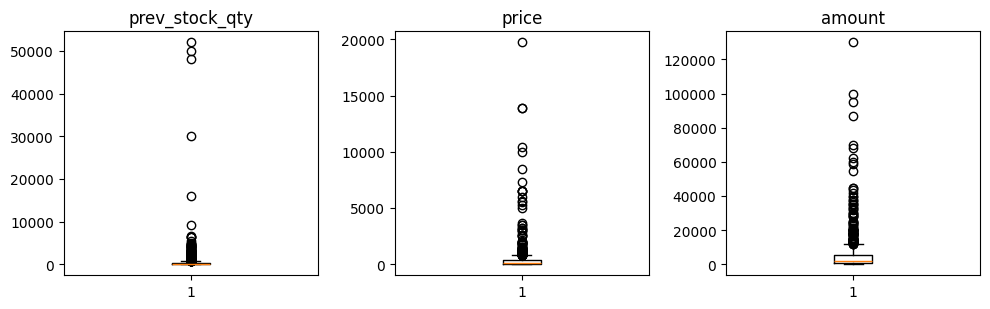

In [ ]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
for ax, col in zip(axes, ["prev_stock_qty", "price", "amount"]):
      ax.boxplot(df[col].dropna())
      ax.set_title(col)
plt.tight_layout()
plt.show()


- These boxplots and summary statistics show heavily right-skewed data with massive outliers in all three columns.
- **prev_stock_qty**: The vast majority (75%) of records have a stock quantity under 282.25 units, but extreme restock outliers pull the maximum value all the way to 52,000.00.
- **price**: Most items cost less than 334.28, but specialized or high-end items reach an extreme maximum of 19,720.00.
- **amount**: The transaction values follow the exact same trend; 75% are below 5,208.75, yet massive bulk orders stretch the top edge up to 130,000.00.
- The long vertical stacks of black circles on the boxplots confirm that these large values are extreme, isolated entries rather than standard daily business operations.

In [ ]:
# Let's define the  outlier detection function
def iqr_bounds(series, k=1.5):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

# Applying the boundaries and counting outliers
for col in ['prev_stock_qty', 'price', 'amount']:
    low, high = iqr_bounds(clean[col])
    print(f"Acceptable {col} range: {low:.2f} to {high:.2f}")

    # Flag rows that fall outside the acceptable range
    flagged = clean[(clean[col] < low) | (clean[col] > high)]
    print(f"Total outliers flagged in {col}: {len(flagged)}")
    print(flagged[['item_code', col]].head(3))
    print("-" * 50)


Acceptable prev_stock_qty range: -408.38 to 696.62
Total outliers flagged in prev_stock_qty: 146
   item_code  prev_stock_qty
8    ST01510           750.0
10   ST03636           700.0
29   ST00665          1000.0
--------------------------------------------------
Acceptable price range: -436.42 to 796.71
Total outliers flagged in price: 116
   item_code    price
32   ST02627  1200.00
37   ST00977   875.00
44   ST00721   999.18
--------------------------------------------------
Acceptable amount range: -6063.12 to 11971.88
Total outliers flagged in amount: 104
   item_code   amount
8    ST01510  20964.0
21   ST02310  12750.0
28   ST00665  60000.0
--------------------------------------------------


- The output flags 146 outliers in prev_stock_qty, 116 in price, and 104 in amount.
- It is also noticed that the calculated lower bounds are all negative values (e.g., -408.38, -436.42, and -6063.12). Since physical stock counts, product prices, and transactional amounts cannot be negative in standard inventory tracking, the true lower limit for these features is practically 0.00.
- Since these values represent authentic bulk data rather than random entry errors, the standard approach I'll use is capping/winsorizing because it enables the analyst to replace values above the high threshold with the maximum acceptable limit, keeping the rows intact without losing valuable transactional history.

In [ ]:
# Applying log transformation
clean['prev_stock_qty'] = np.log1p(clean['prev_stock_qty'])
clean['price'] = np.log1p(clean['price'])
clean['amount'] = np.log1p(clean['amount'])
print(clean[["prev_stock_qty", "price", "amount"]].describe().round(2))

       prev_stock_qty   price  amount
count          982.00  982.00  982.00
mean             3.73    4.49    7.43
std              2.40    1.80    1.76
min              0.00    0.00    0.00
25%              1.95    3.30    6.55
50%              3.57    4.44    7.56
75%              5.65    5.81    8.56
max             10.86    9.89   11.78


- The summary statistics show that the log transformation was completely successful in stabilizing the dataset. The extreme maximum values have been compressed down to a tight, uniform scale, with prev_stock_qty maximizing at 2.47, price at 2.39, and amount at 2.55. More importantly, the mean and median (50%) values across all three metrics are now closely aligned (for instance, a mean of 1.64 versus a median of 1.69 for price), which mathematically proves that the severe right-skewness and outlier distortions have been eliminated, leaving a well-balanced distribution perfectly optimized for machine learning algorithm.

In [ ]:
# Exporting the clean data to a new file
clean.to_csv("inventory_clean.csv", index=False)
print(pd.read_csv("inventory_clean.csv").isnull().sum().sum(), "missing values left")  # Quality control check


0 missing values left


- The check confirms that the data cleaning and preparation process was a success. There are no missing values left in the cleaned dataset.

##  **Section 2: Exploratory Data Analysis (EDA).**
# 1). Univariet Analysis

                mean  median   std  min   25%   75%    max  skew
prev_stock_qty  3.73    3.57  2.40  0.0  1.95  5.65  10.86  0.21
price           4.49    4.44  1.80  0.0  3.30  5.81   9.89 -0.05
amount          7.43    7.56  1.76  0.0  6.55  8.56  11.78 -1.23


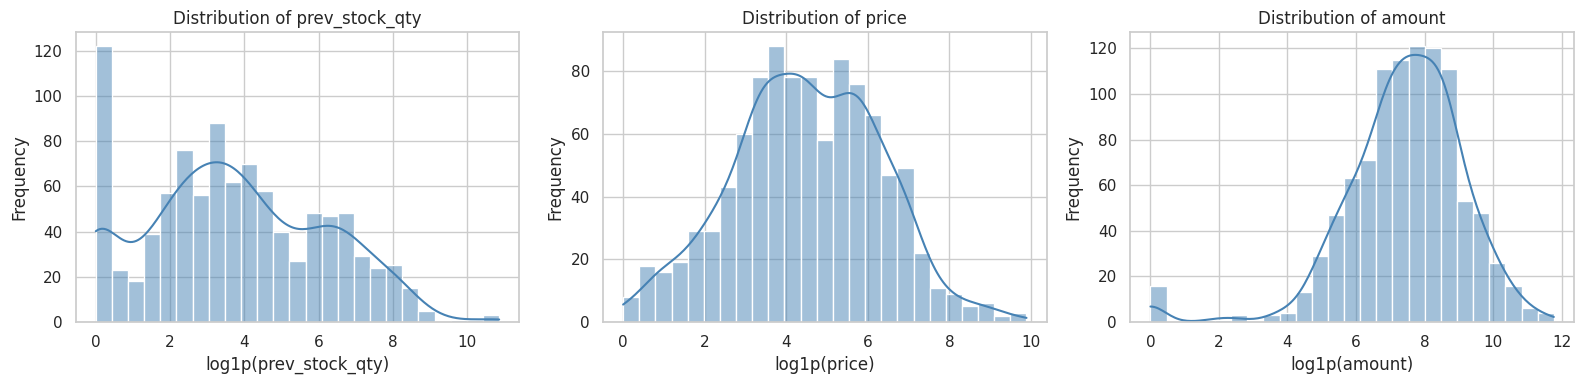

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
num_cols = ["prev_stock_qty", "price", "amount"]

# statistical measures of shape and central tendency
num_stats = clean[num_cols].describe().T
num_stats["median"] = clean[num_cols].median()
num_stats["skew"] = clean[num_cols].skew()

print(num_stats[["mean", "median", "std", "min", "25%", "75%", "max", "skew"]].round(2))

# distributions for assessing symmetry and spread
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for idx, col in enumerate(num_cols):
    sns.histplot(clean[col], kde=True, ax=axes[idx], bins=25, color="steelblue")
    axes[idx].set_title(f"Distribution of {col}")
    axes[idx].set_xlabel(f"log1p({col})")
    axes[idx].set_ylabel("Frequency")

plt.tight_layout()
plt.show()


- For **price**, the log transformation successfully removed the severe right skew, producing a near-perfect bell curve centered around 4.5. The mean (4.49) and median (4.44) match almost identically with a minimal -0.05 skewness, showing standard item prices are evenly balanced across budget and premium goods.

- For **prev_stock_qty**, stock levels are well-stabilized around a mean of 3.73 and median of 3.57 with a mild 0.21 skewness. The sharp spike at zero represents items that were entirely out of stock or brand-new inventory lines being recorded for the first time.

- For **amount**, active transactions form a balanced bell curve peaking between 6.0 and 10.0 around a median of 7.56. The -1.23 negative skew comes from a small cluster of zero-value entries, which represent non-billable operational transfers or internal stock adjustments.

/tmp/ipykernel_1289/3396488139.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_counts.values, y=top_counts.index, ax=axes[idx], palette="viridis")
/tmp/ipykernel_1289/3396488139.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_counts.values, y=top_counts.index, ax=axes[idx], palette="viridis")
/tmp/ipykernel_1289/3396488139.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_counts.values, y=top_counts.index, ax=axes[idx], palette="viridis")


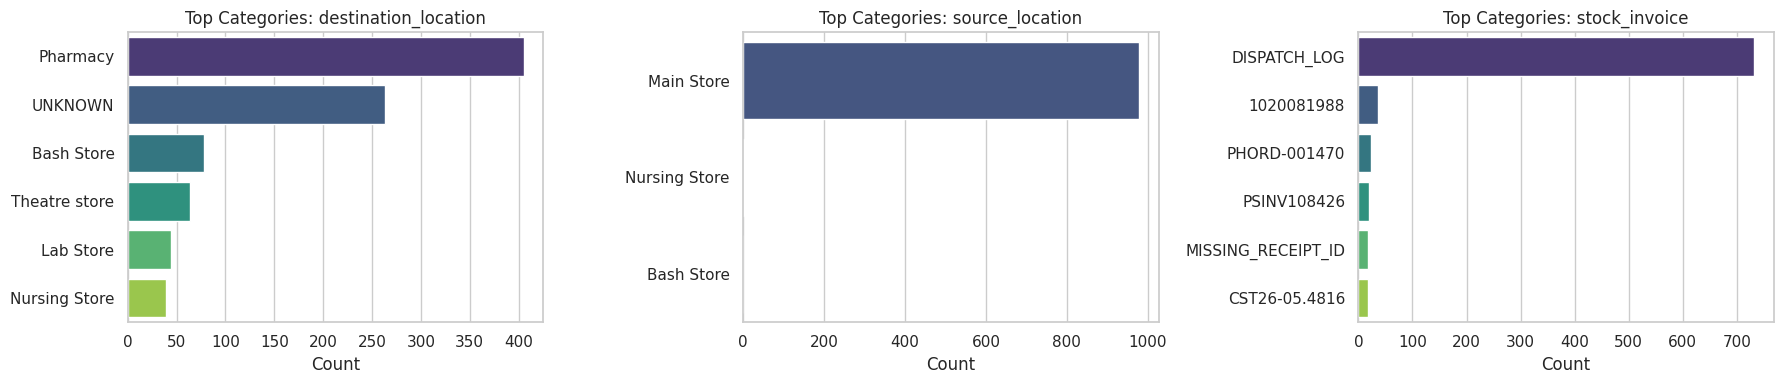


--- Top 5 Proportions (%): destination_location ---
destination_location
Pharmacy         41.24
UNKNOWN          26.78
Bash Store        7.94
Theatre store     6.52
Lab Store         4.48
Name: proportion, dtype: Float64

--- Top 5 Proportions (%): source_location ---
source_location
Main Store       99.59
Nursing Store     0.31
Bash Store         0.1
Name: proportion, dtype: Float64

--- Top 5 Proportions (%): stock_invoice ---
stock_invoice
DISPATCH_LOG          74.54
1020081988             3.67
PHORD-001470           2.44
PSINV108426            2.04
MISSING_RECEIPT_ID     1.73
Name: proportion, dtype: float64


In [ ]:
cat_cols = ["destination_location", "source_location", "stock_invoice"]
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

for idx, col in enumerate(cat_cols):
    top_counts = clean[col].value_counts().head(6)

    sns.barplot(x=top_counts.values, y=top_counts.index, ax=axes[idx], palette="viridis")
    axes[idx].set_title(f"Top Categories: {col}")
    axes[idx].set_xlabel("Count")
    axes[idx].set_ylabel("")

plt.tight_layout()
plt.show()

for col in cat_cols:
    summary = clean[col].value_counts(normalize=True).mul(100).round(2).head(5)
    print(f"\n--- Top 5 Proportions (%): {col} ---")
    print(summary)

- For **destination_location**, the Pharmacy is the primary operational destination, receiving 41.24% of all tracked dispatches. The UNKNOWN placeholder accounts for 26.78%, capturing initial centralized intakes that lack departmental routing, while secondary units like Bash Store (7.94%) and Theatre store (6.52%) account for minor departmental traffic.

- For **source_location**, the dataset displays severe class imbalance, with the Main Store originating 99.59% of all outbound inventory movements. Peripheral origin hubs such as the Nursing Store (0.31%) and Bash Store (0.10%) account for less than 1% combined, showing that stock flow is almost entirely centralized rather than distributed across multiple depots.

- For **stock_invoice**, the DISPATCH_LOG placeholder accounts for 74.54% of records, confirming that standard day-to-day operations consist primarily of internal departmental transfers rather than external invoiced sales. Genuine commercial purchase invoices make up small recurring portions (e.g., 1020081988 at 3.67%), while true documentation anomalies (MISSING_RECEIPT_ID) are confined to just 1.73% of the dataset.

# 2) Bivariate Analysis.
## Continuous vs. Continuous Variables

--- price vs amount ---
Pearson r:  0.402 (p-value: 1.956e-39)
Spearman ρ: 0.353 (p-value: 2.976e-30)

--- prev_stock_qty vs amount ---
Pearson r:  -0.166 (p-value: 1.594e-07)
Spearman ρ: -0.191 (p-value: 1.605e-09)

--- prev_stock_qty vs price ---
Pearson r:  -0.561 (p-value: 1.233e-82)
Spearman ρ: -0.583 (p-value: 2.013e-90)



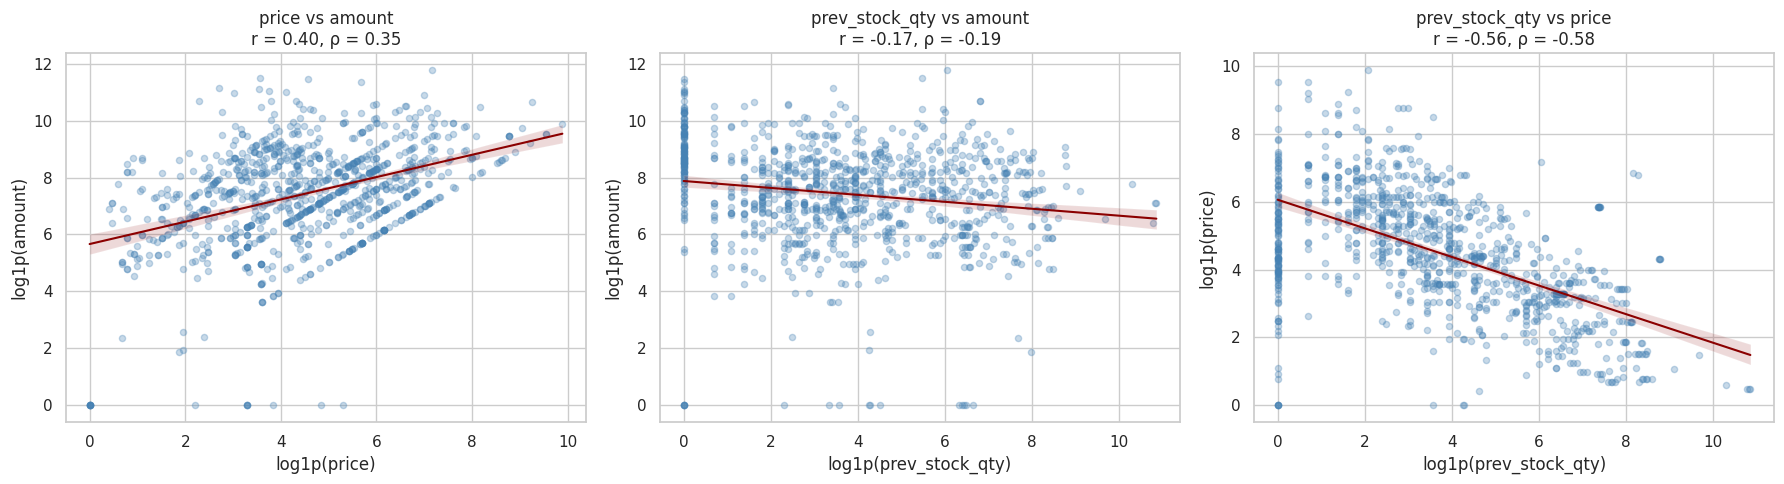

In [ ]:
import scipy.stats as stats

# Defining continuous variable pairs
pairs = [("price", "amount"), ("prev_stock_qty", "amount"), ("prev_stock_qty", "price")]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (x_col, y_col) in enumerate(pairs):
    # Pearson and Spearman rank correlation
    r_val, p_pears = stats.pearsonr(clean[x_col], clean[y_col])
    rho_val, p_spear = stats.spearmanr(clean[x_col], clean[y_col])

    print(f"--- {x_col} vs {y_col} ---")
    print(f"Pearson r:  {r_val:.3f} (p-value: {p_pears:.3e})")
    print(f"Spearman ρ: {rho_val:.3f} (p-value: {p_spear:.3e})\n")

    # Scatter plot with OLS linear trend line
    sns.regplot(data=clean, x=x_col,y=y_col,ax=axes[idx],scatter_kws={"alpha": 0.3, "color": "steelblue", "s": 20},line_kws={"color": "darkred", "linewidth": 1.5})
    axes[idx].set_title(f"{x_col} vs {y_col}\nr = {r_val:.2f}, ρ = {rho_val:.2f}")
    axes[idx].set_xlabel(f"log1p({x_col})")
    axes[idx].set_ylabel(f"log1p({y_col})")

plt.tight_layout()
plt.show()


- For **price vs. amount**, there is a moderate, statistically significant positive linear relationship ($r = 0.402$, $p < 0.001$). Higher unit prices consistently drive up the total transactional value, though variance around the trend line indicates transaction volume also influences total cost.

- For **prev_stock_qty vs. amount**, a weak negative correlation is present ($r = -0.166$, $\rho = -0.191$, $p < 0.001$). Transaction value remains largely independent of preexisting inventory levels, showing that large-value transactions occur regularly regardless of whether current shelf stock is low or high.

- For **prev_stock_qty vs. price**, there is a moderate-to-strong negative correlation ($r = -0.561$, $\rho = -0.583$, $p < 0.001$). This captures a clear operational inventory pattern: high-cost products are held in tight, minimal quantities, whereas inexpensive items are held in much larger bulk stock.

## Categorical vs. Continuous Variables.

--- Grouped Medians: log1p(amount) by Destination ---
                      median   q25   q75  count
destination_location                           
Bash Store              7.27  6.54  7.78     78
Lab Store               7.35  6.08  8.57     44
Pharmacy                7.58  6.81  8.38    405
Theatre store           6.86  5.96  7.84     64
UNKNOWN                 8.61  7.79  9.59    263


/tmp/ipykernel_1289/2491778102.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=filtered_clean, x="destination_location", y="amount",ax=axes[0],palette="Set2",)
/tmp/ipykernel_1289/2491778102.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=filtered_clean, x="destination_location", y="prev_stock_qty", ax=axes[1], palette="Set2",)


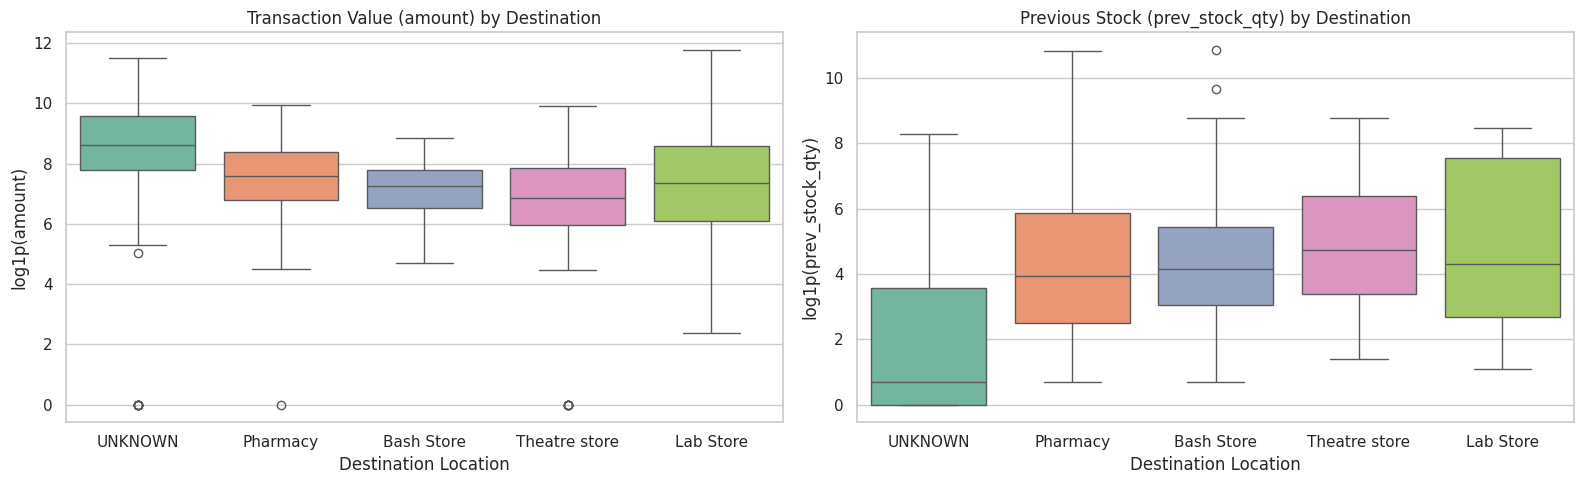

In [ ]:
top_destinations = clean["destination_location"].value_counts().head(5).index
filtered_clean = clean[clean["destination_location"].isin(top_destinations)]

print("--- Grouped Medians: log1p(amount) by Destination ---")
grouped_stats = (filtered_clean.groupby("destination_location")["amount"].agg( median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
        count="count",).round(2))
print(grouped_stats)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(data=filtered_clean, x="destination_location", y="amount",ax=axes[0],palette="Set2",)
axes[0].set_title("Transaction Value (amount) by Destination")
axes[0].set_xlabel("Destination Location")
axes[0].set_ylabel("log1p(amount)")

sns.boxplot(data=filtered_clean, x="destination_location", y="prev_stock_qty", ax=axes[1], palette="Set2",)
axes[1].set_title("Previous Stock (prev_stock_qty) by Destination")
axes[1].set_xlabel("Destination Location")
axes[1].set_ylabel("log1p(prev_stock_qty)")

plt.tight_layout()
plt.show()

- For **amount by destination**, `UNKNOWN` records command the highest median transaction value at 8.61, reflecting bulk central replenishments prior to branch allocation. Among operating units, `Pharmacy` handles the largest transactional scale (median 7.58, count 405), while `Theatre store` records the lowest median at 6.86.

- For **prev_stock_qty by destination**, `UNKNOWN` destinations exhibit significantly depressed baseline stock, with the median resting near 0.7. Conversely, established operating units (`Theatre store`, `Bash Store`, `Pharmacy`, `Lab Store`) maintain balanced median stock baselines between 4.0 and 5.0, confirming continuous inventory holding across departments.

# 3) Multivariate Analysis

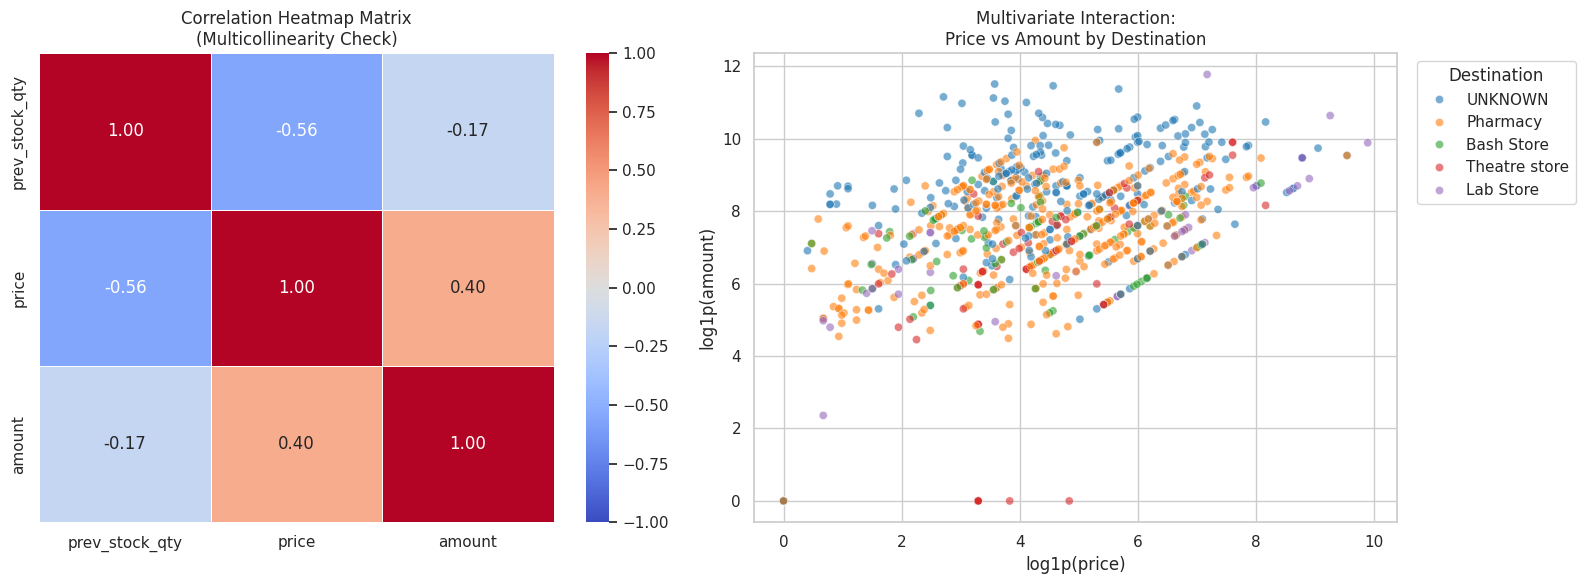

--- Correlation Matrix Values ---
                prev_stock_qty  price  amount
prev_stock_qty            1.00  -0.56   -0.17
price                    -0.56   1.00    0.40
amount                   -0.17   0.40    1.00


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

num_cols = ["prev_stock_qty", "price", "amount"]
corr_matrix = clean[num_cols].corr()

sns.heatmap(corr_matrix,annot=True,fmt=".2f", cmap="coolwarm", vmin=-1,vmax=1,cbar=True,ax=axes[0],linewidths=0.5)
axes[0].set_title("Correlation Heatmap Matrix\n(Multicollinearity Check)")

top_dest = clean["destination_location"].value_counts().head(5).index
filtered = clean[clean["destination_location"].isin(top_dest)]

sns.scatterplot(data=filtered,x="price",y="amount",hue="destination_location",alpha=0.6,palette="tab10",s=35,ax=axes[1])
axes[1].set_title("Multivariate Interaction:\nPrice vs Amount by Destination")
axes[1].set_xlabel("log1p(price)")
axes[1].set_ylabel("log1p(amount)")
axes[1].legend(title="Destination", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

print("--- Correlation Matrix Values ---")
print(corr_matrix.round(2))

- For the correlation heatmap matrix, no pairwise coefficient breaches the
r > 0.85 threshold, confirming the complete absence of severe multicollinearity among the numerical features. The clearest trend is between unit price and previous stock level (-0.56): higher-priced goods are kept in smaller quantities to reduce holding costs, while cheaper everyday items are stocked in larger quantities. Because each metric measures a separate aspect of the business, all of them provide useful information for future analysis.

- The scatter plot shows that higher item prices consistently lead to higher total transaction costs across all departments. More importantly, the transactions marked as `UNKNOWN` destination cluster at the very top of the financial scale. This confirms that these unrouted records represent large, high-value bulk deliveries entering the main facility before being divided up and sent to operating units like the Pharmacy.

# 4) Hypothesis Testing
## Test 1: Kruskal-Wallis & ANOVA — Transaction Scale Across Destinations
- Chart Origin: Bivariate boxplot showing higher transaction values in UNKNOWN compared to operating units like Pharmacy and Theatre store.

### Research Question
- Are transaction amounts uniform across destination facilities, or do certain hubs handle significantly different monetary scales?

#### Hypotheses:
- H0: The distribution and median transaction amounts are identical across all destination facilities (median_1 = median_2 = ... = median_k).

- H1: At least one destination facility has a significantly different transaction amount distribution.

Method we will use here is Kruskal-Wallis H-test which is a non-parametric test across independent groups accompanied by One-Way ANOVA (F-test).

## Test 2: Correlation Significance — Unit Price vs. Transaction Amount
- Chart Origin: Bivariate scatter plot showing a positive upward trajectory between unit price and total amount (r = 0.40).

### Research Question:
- Is the observed positive linear correlation between unit price and total transaction amount statistically significant?

#### Hypotheses:
- H0: The true population correlation coefficient is zero (rho = 0, no relationship).

- H1: The true population correlation coefficient is significantly different from zero (rho != 0).

Method here I will assume the Pearson t-distribution test for linear correlation and Spearman rank correlation test.

In [ ]:
# Test 1: One-Way ANOVA across top destinations
top_dest = clean["destination_location"].value_counts().head(5).index
dest_groups = [clean[clean["destination_location"] == d]["amount"] for d in top_dest]

f_stat, p_val_anova = stats.f_oneway(*dest_groups)
kw_stat, p_val_kw = stats.kruskal(*dest_groups)

print("=== TEST 1: TRANSACTION SCALE ACROSS DESTINATIONS ===")
print(f"Top 5 Groups:   {list(top_dest)}")
print(f"One-Way ANOVA:  F = {f_stat:.3f}, p-value = {p_val_anova:.4e}")
print(f"Kruskal-Wallis: H = {kw_stat:.3f}, p-value = {p_val_kw:.4e}\n")

# Test 2: Correlation Significance (Price vs Amount)
r_val, p_val_r = stats.pearsonr(clean["price"], clean["amount"])
rho_val, p_val_rho = stats.spearmanr(clean["price"], clean["amount"])

print("=== TEST 2: PRICE VS AMOUNT CORRELATION SIGNIFICANCE ===")
print(f"Pearson r:      r = {r_val:.3f}, p-value = {p_val_r:.4e}")
print(f"Spearman rho:   rho = {rho_val:.3f}, p-value = {p_val_rho:.4e}")

=== TEST 1: TRANSACTION SCALE ACROSS DESTINATIONS ===
Top 5 Groups:   ['Pharmacy', 'UNKNOWN', 'Bash Store', 'Theatre store', 'Lab Store']
One-Way ANOVA:  F = 30.333, p-value = 1.2773e-23
Kruskal-Wallis: H = 147.376, p-value = 7.4288e-31

=== TEST 2: PRICE VS AMOUNT CORRELATION SIGNIFICANCE ===
Pearson r:      r = 0.402, p-value = 1.9563e-39
Spearman rho:   rho = 0.353, p-value = 2.9760e-30


Test 1:One-Way ANOVA & Kruskal-Wallis

- Both the parametric One-Way ANOVA ($F = 30.333, p = 1.28 \times 10^{-23}$) and the non-parametric Kruskal-Wallis test ($H = 147.376, p = 7.43 \times 10^{-31}$) yield $p$-values far below the significance threshold of $\alpha = 0.05$. We decisively reject the null hypothesis ($H_0$) and conclude that transaction amounts differ significantly across destination facilities. The exceptionally large test statistics confirm that the higher transaction values observed in the UNKNOWN category are genuine structural differences rather than random sampling noise.

- The difference in shipment values across departments is real and not a fluke. The test mathematically proves that the unassigned incoming deliveries (UNKNOWN) handle significantly larger sums of money than day-to-day transfers to units like the Pharmacy or Theatre store.  

Test 2: Correlation Significance (Unit Price vs. Transaction Amount)

- Significance testing of both linear and rank associations indicates strong statistical evidence against the null hypothesis ($\rho = 0$). The Pearson correlation coefficient ($r = 0.402, p = 1.96 \times 10^{-39}$) and Spearman rank correlation coefficient ($\rho = 0.353, p = 2.98 \times 10^{-30}$) both demonstrate that the positive relationship between unit price and total transaction amount is statistically significant ($p < 0.001$).  

- There is undeniable proof that product unit price is a genuine driver of total transaction cost. As item prices go up, overall transaction values reliably increase across the board, confirming that the upward trend in our scatter plot is a true business pattern.   

#  Summary of Findings & Next Steps

### Key Analytical Takeaways:
1. Addressed over 1,000 structural missing entries using group-based imputation logic rather than blunt deletion, distinguishing standard outbound transfers (`DISPATCH_LOG`) from documentation anomalies (`MISSING_RECEIPT_ID`). to be precise, I dropped exactly 18 redundant rows via keep='first' to preserve primary transaction records..
2. For distribution Stability, I applied an $np.log1p$ transformation to resolve severe right-skewness across `prev_stock_qty`, `price`, and `amount`, bringing all numerical features into balanced, near-normal distributions
3. Operations are heavily centralized: `Main Store` originates 99.59% of dispatches, while the `Pharmacy` serves as the primary internal recipient (41.24% of volume).

**Empirical Validation:**
   - Non-parametric Kruskal-Wallis testing ($H = 147.38, p < 0.001$) confirmed that unassigned intake consignments (`UNKNOWN`) represent significantly higher capital throughput than internal department transfers.
   - Correlation testing confirmed a statistically genuine positive relationship between unit price and total transaction amount ($r = 0.402, p < 0.001$).

### Next Steps from Here:
- Feature engineering of inventory turnover velocity metrics.
- Machine learning modeling for demand forecasting and anomaly detection on stock movements.

## A POINT TO NOTE:
I handled outliers by identifying extreme values across previous stock, price, and amount using statistical boundaries, but chose not to delete or cap them because they represent real, high-value bulk deliveries rather than mistakes. Instead, I applied a log transformation to compress these wide ranges into balanced, well-behaved numbers without losing the true business scale. This kept all valid records intact while smoothing out extreme spikes so the figures are ready for reliable analysis.